In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [3]:
import io

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 200
Number of columns: 5

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0


In [6]:

df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


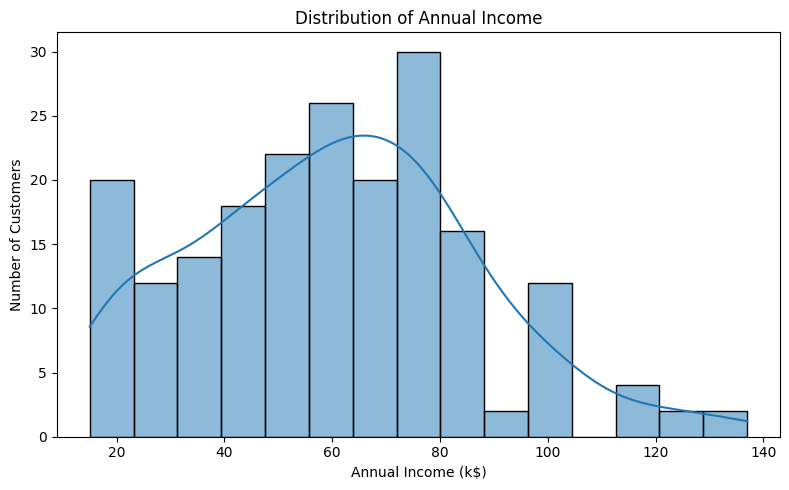

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Annual Income (k$)'],
    bins=15,
    kde=True
)

plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

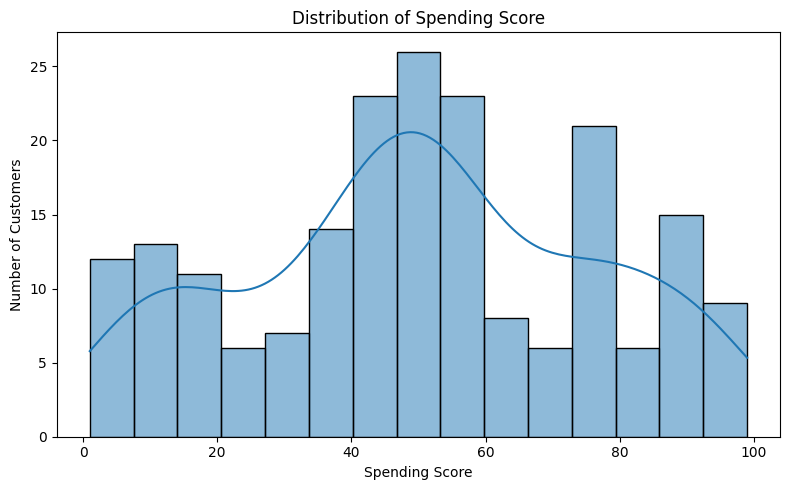

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Spending Score (1-100)'],
    bins=15,
    kde=True
)

plt.title('Distribution of Spending Score')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

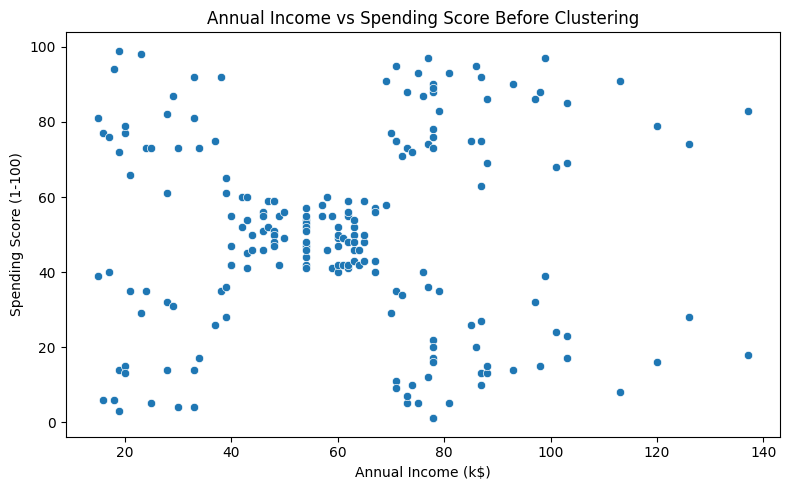

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)'
)

plt.title('Annual Income vs Spending Score Before Clustering')
plt.tight_layout()
plt.show()

In [10]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

print("Selected features:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Missing values:
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed!
Scaled data shape: (200, 2)


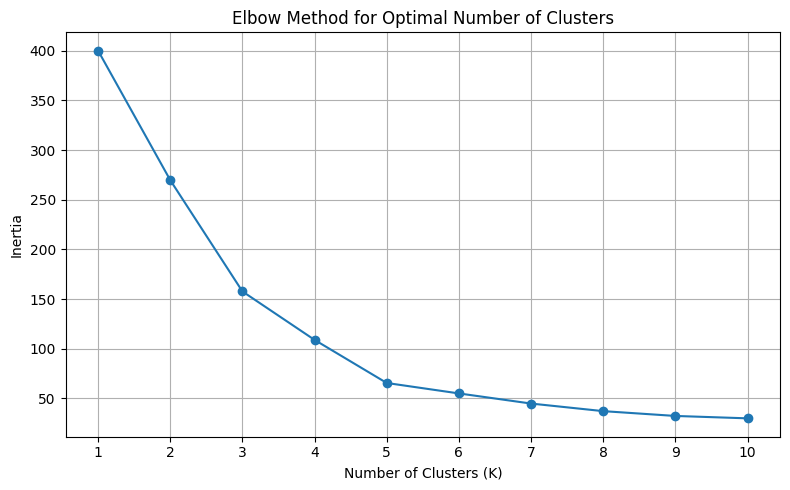

In [12]:
# Elbow Method to find the suitable number of clusters

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
# Compare silhouette scores for different cluster numbers

silhouette_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        'Number of Clusters': k,
        'Silhouette Score': score
    })

silhouette_df = pd.DataFrame(silhouette_results)

print(silhouette_df.round(3))

   Number of Clusters  Silhouette Score
0                   2             0.321
1                   3             0.467
2                   4             0.494
3                   5             0.555
4                   6             0.540
5                   7             0.528
6                   8             0.455
7                   9             0.457
8                  10             0.443


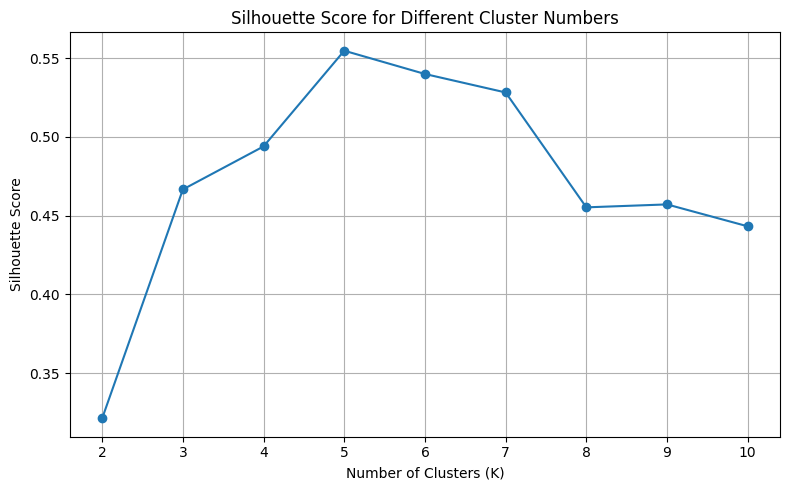

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_df['Number of Clusters'],
    silhouette_df['Silhouette Score'],
    marker='o'
)

plt.title('Silhouette Score for Different Cluster Numbers')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
# Apply K-Means clustering

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

print("\nCustomers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

K-Means clustering completed!

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


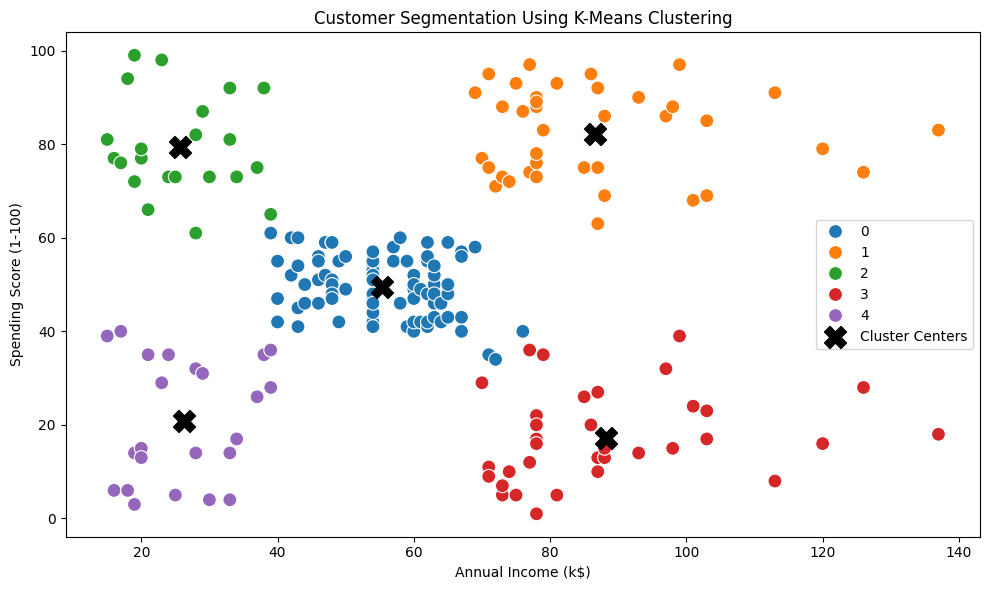

In [16]:
# Visualize the customer clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='tab10',
    s=100
)

# Mark cluster centers
centers_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    marker='X',
    s=250,
    color='black',
    label='Cluster Centers'
)

plt.title('Customer Segmentation Using K-Means Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
# Analyze characteristics of each cluster

cluster_summary = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Annual_Income=('Annual Income (k$)', 'mean'),
    Average_Spending_Score=('Spending Score (1-100)', 'mean')
).round(2)

print("Cluster Characteristics:")
print(cluster_summary)

Cluster Characteristics:
         Customer_Count  Average_Age  Average_Annual_Income  \
Cluster                                                       
0                    81        42.72                  55.30   
1                    39        32.69                  86.54   
2                    22        25.27                  25.73   
3                    35        41.11                  88.20   
4                    23        45.22                  26.30   

         Average_Spending_Score  
Cluster                          
0                         49.52  
1                         82.13  
2                         79.36  
3                         17.11  
4                         20.91  


In [18]:
# Calculate percentage of customers in each cluster

cluster_percentage = (
    df['Cluster']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Customer Percentage by Cluster:")
print(cluster_percentage)

Customer Percentage by Cluster:
Cluster
0    40.5
1    19.5
2    11.0
3    17.5
4    11.5
Name: proportion, dtype: float64


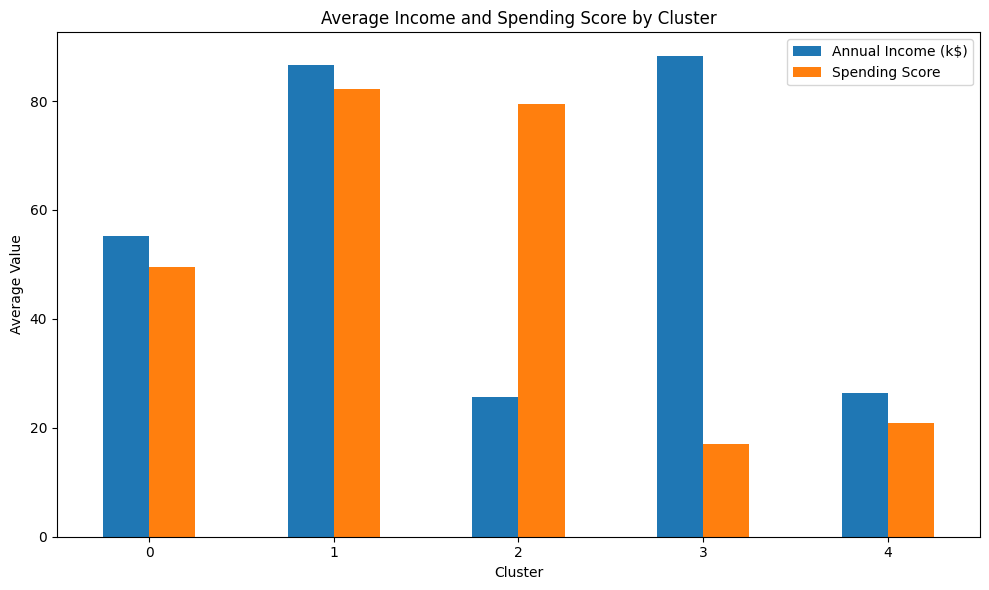

In [19]:
# Compare average income and spending score

cluster_summary[
    ['Average_Annual_Income', 'Average_Spending_Score']
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Income and Spending Score by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(['Annual Income (k$)', 'Spending Score'])
plt.tight_layout()
plt.show()

In [20]:
# Evaluate the clustering model

final_silhouette = silhouette_score(
    X_scaled,
    df['Cluster']
)

print("Number of clusters:", df['Cluster'].nunique())
print("Silhouette Score:", round(final_silhouette, 3))
print("Inertia:", round(kmeans.inertia_, 3))

Number of clusters: 5
Silhouette Score: 0.555
Inertia: 65.568


In [21]:
# Save the final results

df.to_csv('Week_3_Clustered_Customers.csv', index=False)

cluster_summary.to_csv('Week_3_Cluster_Summary.csv')

print("Files saved successfully!")

Files saved successfully!


In [22]:
from google.colab import files

files.download('Week_3_Clustered_Customers.csv')
files.download('Week_3_Cluster_Summary.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# Display detailed cluster characteristics

print("WEEK 3: CLUSTER ANALYSIS")
print("=" * 50)

display(cluster_summary)

print("\nLargest cluster:")
print(cluster_summary['Customer_Count'].idxmax())

print("\nHighest average income cluster:")
print(cluster_summary['Average_Annual_Income'].idxmax())

print("\nHighest average spending score cluster:")
print(cluster_summary['Average_Spending_Score'].idxmax())

WEEK 3: CLUSTER ANALYSIS


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91



Largest cluster:
0

Highest average income cluster:
3

Highest average spending score cluster:
1


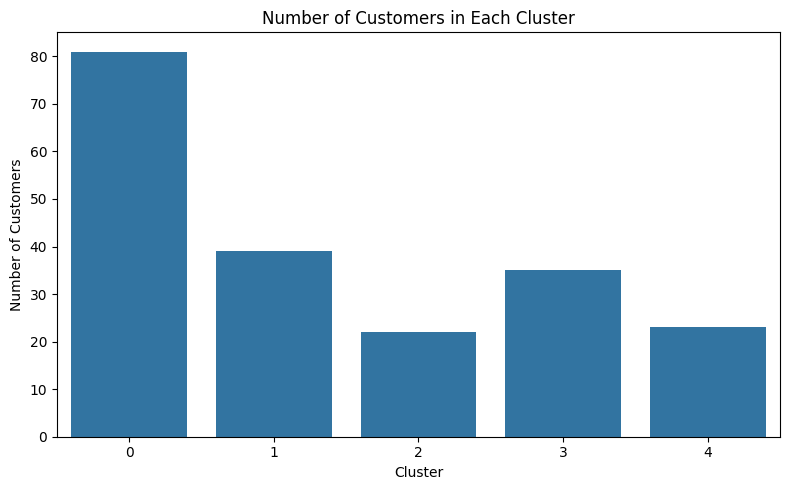

In [24]:
# Visualize the number of customers in each cluster

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_summary.index,
    y=cluster_summary['Customer_Count']
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [25]:
# Save cluster analysis results

cluster_summary.to_csv(
    'Week_3_Cluster_Characteristics.csv',
    index=True
)

print("Cluster characteristics saved successfully!")

Cluster characteristics saved successfully!


In [26]:
from google.colab import files

files.download('Week_3_Cluster_Characteristics.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
display(cluster_summary)

,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [28]:
print("Silhouette Score:", round(final_silhouette, 3))
print("\nCluster-wise Customer Count:")
print(df['Cluster'].value_counts().sort_index())

Silhouette Score: 0.555

Cluster-wise Customer Count:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [29]:
print("WEEK 3 CLUSTERING ANALYSIS SUMMARY")
print("=" * 45)

print("Total customers:", len(df))
print("Number of clusters:", df['Cluster'].nunique())
print("Silhouette Score:", round(final_silhouette, 3))

print("\nCluster Summary:")
display(cluster_summary)

print("\nMissing values in dataset:")
print(df.isnull().sum().sum())

WEEK 3 CLUSTERING ANALYSIS SUMMARY
Total customers: 200
Number of clusters: 5
Silhouette Score: 0.555

Cluster Summary:


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91



Missing values in dataset:
0


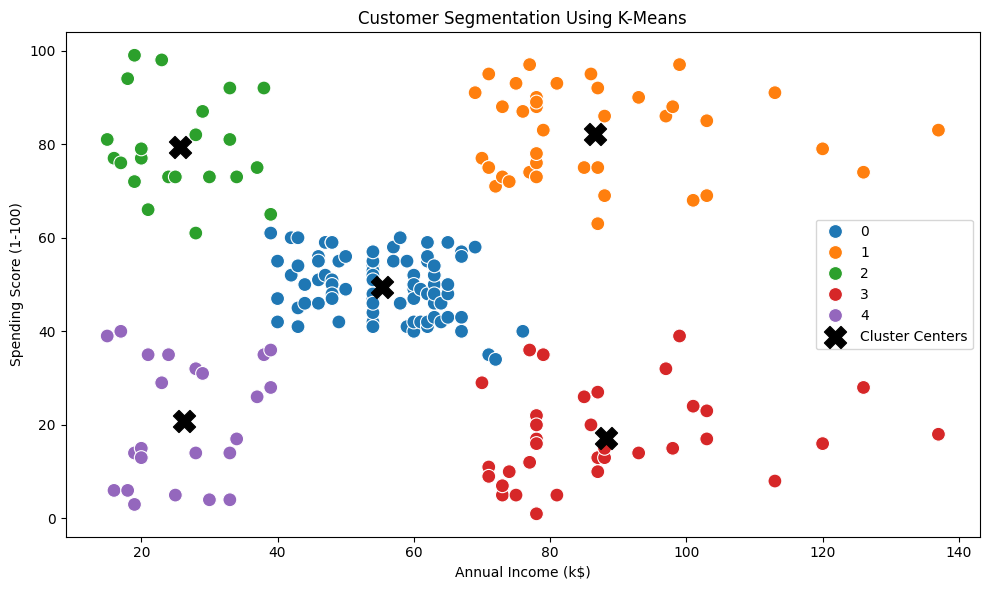

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='tab10',
    s=100
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    color='black',
    s=250,
    label='Cluster Centers'
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.tight_layout()
plt.show()

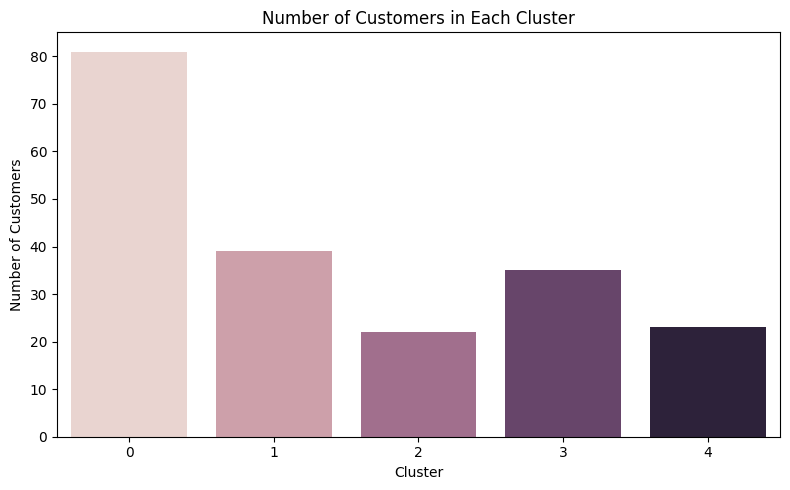

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Cluster', hue='Cluster', legend=False)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

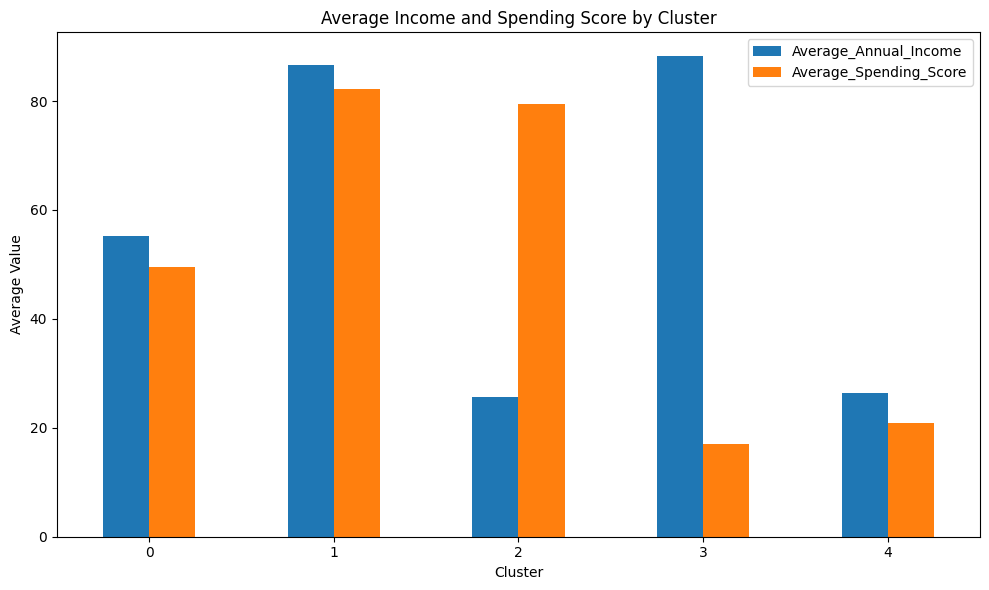

In [32]:
cluster_summary[
    ['Average_Annual_Income', 'Average_Spending_Score']
].plot(kind='bar', figsize=(10, 6))

plt.title('Average Income and Spending Score by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
print("FINAL MODEL EVALUATION")
print("=" * 40)

print("Total customers:", len(df))
print("Number of clusters:", df['Cluster'].nunique())
print("Silhouette Score:", round(final_silhouette, 3))
print("Inertia:", round(kmeans.inertia_, 3))

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nCluster summary:")
display(cluster_summary)

FINAL MODEL EVALUATION
Total customers: 200
Number of clusters: 5
Silhouette Score: 0.555
Inertia: 65.568

Missing values: 0
Duplicate rows: 0

Cluster summary:


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


## Limitations of the Analysis

This analysis uses Annual Income and Spending Score as the main clustering features. The results depend on the selected features, the number of clusters, and the K-Means algorithm. The customer groups describe patterns in the dataset and do not prove the reasons behind customer behaviour. The dataset is also limited in size, so the findings may not represent all supermarket or retail customers.

## Conclusion

This project applied K-Means clustering to the Mall Customers dataset to identify customer segments based on annual income and spending score. Data exploration, feature scaling, the Elbow Method, Silhouette Score evaluation, and cluster visualization were used during the analysis. Five customer groups were examined to understand differences in their income and spending patterns. These segments can help businesses consider suitable marketing strategies for different customer groups. The results are exploratory and should be validated with additional customer data before making business decisions.

## Learning Outcomes

Through this project, I gained practical experience in unsupervised learning, data preprocessing, feature scaling, K-Means clustering, model evaluation, visualization, and cluster interpretation using Python and Scikit-learn.

In [35]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSelected clustering features:")
display(X.head())

Dataset shape: (200, 6)

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
Cluster                   0
dtype: int64

Duplicate rows: 0

Selected clustering features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [36]:
print("ELBOW METHOD RESULTS")
for k, inertia in zip(k_values, inertia_values):
    print(f"K={k}: Inertia={inertia:.3f}")

print("\nSILHOUETTE SCORE RESULTS")
display(silhouette_df.round(3))

ELBOW METHOD RESULTS
K=1: Inertia=400.000
K=2: Inertia=269.691
K=3: Inertia=157.704
K=4: Inertia=108.921
K=5: Inertia=65.568
K=6: Inertia=55.057
K=7: Inertia=44.865
K=8: Inertia=37.228
K=9: Inertia=32.392
K=10: Inertia=29.982

SILHOUETTE SCORE RESULTS


,Number of Clusters,Silhouette Score
0,2,0.321
1,3,0.467
2,4,0.494
3,5,0.555
4,6,0.540
5,7,0.528
6,8,0.455
7,9,0.457
8,10,0.443


In [37]:
print("CLUSTER CENTERS")
centers_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers_df = pd.DataFrame(
    centers_original,
    columns=['Annual Income (k$)', 'Spending Score (1-100)']
)

display(centers_df.round(2))

print("\nCLUSTER SUMMARY")
display(cluster_summary)

CLUSTER CENTERS


,Annual Income (k$),Spending Score (1-100)
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91



CLUSTER SUMMARY


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [38]:
cluster_percentage = (
    df['Cluster']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Customer Percentage in Each Cluster:")
print(cluster_percentage)

Customer Percentage in Each Cluster:
Cluster
0    40.5
1    19.5
2    11.0
3    17.5
4    11.5
Name: proportion, dtype: float64


In [39]:
print("WEEK 3 FINAL CHECK")
print("=" * 40)

print("Total customers:", len(df))
print("Total clusters:", df['Cluster'].nunique())
print("Silhouette Score:", round(final_silhouette, 3))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(cluster_summary)

WEEK 3 FINAL CHECK
Total customers: 200
Total clusters: 5
Silhouette Score: 0.555
Missing values: 0
Duplicate rows: 0


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91
